# installing package

In [273]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# imports

In [274]:
from pathlib import Path
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    KFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# settings

In [275]:
RANDOM_STATE = 42
RATE_INR_PER_HOUR = 1_200


DATA_PATH = Path("data/synthetic_projects_raw.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}."
    )

sns.set_theme(style="whitegrid")

# load and inspect

In [276]:
raw_df = pd.read_csv(DATA_PATH)

print("Rows and columns:", raw_df.shape)

Rows and columns: (400, 18)


In [277]:
print("\nColumn names are:")
print(raw_df.columns.tolist())


Column names are:
['project_id', 'project_name', 'project_type', 'num_modules', 'num_user_roles', 'num_integrations', 'payment_gateway_required', 'admin_panel_required', 'mobile_app_required', 'ai_ml_required', 'ui_ux_complexity', 'backend_complexity', 'num_developers', 'developer_experience', 'development_hours', 'duration_days', 'development_cost_inr', 'complexity_level']


In [278]:
print("\nData types are:")
display(raw_df.dtypes.rename("dtype"))


Data types are:


project_id                   object
project_name                 object
project_type                 object
num_modules                  object
num_user_roles              float64
num_integrations             object
payment_gateway_required     object
admin_panel_required         object
mobile_app_required          object
ai_ml_required               object
ui_ux_complexity             object
backend_complexity           object
num_developers               object
developer_experience         object
development_hours             int64
duration_days                 int64
development_cost_inr          int64
complexity_level             object
Name: dtype, dtype: object

In [279]:
print("\nMissing values in raw data are as follows:")
display(raw_df.isna().sum().rename("missing_count"))


Missing values in raw data are as follows:


project_id                   0
project_name                 0
project_type                12
num_modules                 12
num_user_roles              12
num_integrations            12
payment_gateway_required     0
admin_panel_required         0
mobile_app_required          0
ai_ml_required               0
ui_ux_complexity            12
backend_complexity          12
num_developers              12
developer_experience        12
development_hours            0
duration_days                0
development_cost_inr         0
complexity_level             0
Name: missing_count, dtype: int64

In [280]:
print("\n Displaying first 5 rows:")
display(raw_df.head())


 Displaying first 5 rows:


,project_id,project_name,project_type,num_modules,num_user_roles,num_integrations,payment_gateway_required,admin_panel_required,mobile_app_required,ai_ml_required,ui_ux_complexity,backend_complexity,num_developers,developer_experience,development_hours,duration_days,development_cost_inr,complexity_level
0,PRJ-0001,Synthetic Project 0001,CRM,11,4.0,3,No,Yes,No,No,High,Low,7,Mid-level,798,26,957600,Medium
1,PRJ-0002,Synthetic Project 0002,Mobile Application,4,5.0,NaN,No,Yes,Yes,No,Medium,Low,6,Mixed,519,26,622800,Medium
2,PRJ-0003,Synthetic Project 0003,E-commerce,4,4.0,NaN,No,No,No,No,Medium,Low,3,Junior,409,24,490800,Medium
3,PRJ-0004,Synthetic Project 0004,E-commerce,14,6.0,2,Yes,Yes,No,No,Low,Medium,8,Mid-level,713,18,855600,Medium
4,PRJ-0005,Synthetic Project 0005,E-commerce,15,4.0,1,Yes,Yes,No,No,Medium,Medium,7,Senior,685,22,822000,Medium


In [281]:
REQUIRED_COLUMNS = [
    "project_id",
    "project_name",
    "project_type",
    "num_modules",
    "num_user_roles",
    "num_integrations",
    "payment_gateway_required",
    "admin_panel_required",
    "mobile_app_required",
    "ai_ml_required",
    "ui_ux_complexity",
    "backend_complexity",
    "num_developers",
    "developer_experience",
    "development_hours",
    "duration_days",
    "development_cost_inr",
    "complexity_level",
]

In [282]:
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(raw_df.columns))
unexpected_columns = sorted(set(raw_df.columns) - set(REQUIRED_COLUMNS))

In [283]:
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

In [284]:
print("Missing required columns:", missing_columns)
print("Unexpected columns:", unexpected_columns)

Missing required columns: []
Unexpected columns: []


In [285]:
print("Duplicate full rows:", raw_df.duplicated().sum())
print("Duplicate project IDs:", raw_df["project_id"].duplicated().sum())
assert raw_df["project_id"].is_unique

Duplicate full rows: 0
Duplicate project IDs: 0


# input fields, target fields and rules

In [286]:
RAW_FORM_FEATURES = [
    "project_type",
    "num_modules",
    "num_user_roles",
    "num_integrations",
    "payment_gateway_required",
    "admin_panel_required",
    "mobile_app_required",
    "ai_ml_required",
    "ui_ux_complexity",
    "backend_complexity",
    "num_developers",
    "developer_experience",
]

In [287]:
TARGET_COLUMNS = [
    "development_hours",
    "duration_days",
    "development_cost_inr",
    "complexity_level",
]

In [288]:
ALLOWED_CATEGORIES = {
    "project_type": [
        "Web Application",
        "Mobile Application",
        "SaaS",
        "E-commerce",
        "CRM",
        "ERP",
        "AI/ML",
        "Other",
    ],
    "payment_gateway_required": ["Yes", "No"],
    "admin_panel_required": ["Yes", "No"],
    "mobile_app_required": ["Yes", "No"],
    "ai_ml_required": ["Yes", "No"],
    "ui_ux_complexity": ["Low", "Medium", "High"],
    "backend_complexity": ["Low", "Medium", "High"],
    "developer_experience": ["Junior", "Mid-level", "Senior", "Mixed"],
    "complexity_level": ["Low", "Medium", "High", "Very High"],
}

NUMERIC_RANGES = {
    "num_modules": (2, 15),
    "num_user_roles": (1, 8),
    "num_integrations": (0, 6),
    "num_developers": (1, 8),
    "development_hours": (1, 10_000),
    "duration_days": (1, 365),
    "development_cost_inr": (1, 20_000_000),
}

INTEGER_COLUMNS = [
    "num_modules",
    "num_user_roles",
    "num_integrations",
    "num_developers",
    "development_hours",
    "duration_days",
    "development_cost_inr",
]

# cleaning the fields

In [289]:
df = raw_df.copy()
quality_issues = []

In [290]:
def record_issue(row_index, column, issue, original_value, detail):
    quality_issues.append({
        "csv_row_number": row_index + 2,  
        "project_id": df.at[row_index, "project_id"],
        "column": column,
        "issue": issue,
        "original_value": str(original_value),
        "detail": detail,
    })

In [291]:
# Record missing values found 
for column in df.columns:
    for row_index in df.index[df[column].isna()]:
        record_issue(
            row_index,
            column,
            "missing_value",
            "",
            "Value is missing in the raw CSV.",
        )


In [292]:
# catagorical

CATEGORY_ALIASES = {
    ("developer_experience", "mid level"): "Mid-level",
}

for column, allowed_values in ALLOWED_CATEGORIES.items():
    allowed_lookup = {
        " ".join(value.strip().casefold().split()): value
        for value in allowed_values
    }

    for row_index in df.index:
        original = df.at[row_index, column]

        if pd.isna(original):
            continue

        normalized = " ".join(str(original).strip().casefold().split())
        alias_value = CATEGORY_ALIASES.get((column, normalized))

        if alias_value is not None:
            normalized = alias_value.casefold()

        canonical = allowed_lookup.get(normalized)

        if canonical is None:
            record_issue(
                row_index,
                column,
                "unknown_category",
                original,
                f"Expected one of: {allowed_values}",
            )
            df.at[row_index, column] = np.nan

        else:
            if str(original) != canonical:
                record_issue(
                    row_index,
                    column,
                    "category_normalized",
                    original,
                    f"Normalized to {canonical!r}.",
                )
            df.at[row_index, column] = canonical


In [293]:
numeric_pattern = re.compile(r"^\s*([+-]?\d+(?:\.\d+)?)\s*([A-Za-z ]*)\s*$")

for column in NUMERIC_RANGES:
    parsed_values = []

    for row_index, original in df[column].items():
        if pd.isna(original):
            parsed_values.append(np.nan)
            continue

        match = numeric_pattern.fullmatch(str(original))

        if match is None:
            record_issue(
                row_index,
                column,
                "unparseable_numeric",
                original,
                "Could not safely parse this value as a number.",
            )
            parsed_values.append(np.nan)
            continue

        number = float(match.group(1))
        suffix = match.group(2).strip()

        if suffix:
            record_issue(
                row_index,
                column,
                "numeric_suffix_removed",
                original,
                f"Parsed {number:g}; found suffix {suffix!r}.",
            )

        if column in INTEGER_COLUMNS and not number.is_integer():
            record_issue(
                row_index,
                column,
                "non_integer_value",
                original,
                "Expected a whole number; value set missing.",
            )
            parsed_values.append(np.nan)
            continue

        minimum, maximum = NUMERIC_RANGES[column]

        if not minimum <= number <= maximum:
            record_issue(
                row_index,
                column,
                "out_of_range",
                original,
                f"Expected a value from {minimum} to {maximum}.",
            )
            parsed_values.append(np.nan)
            continue

        parsed_values.append(int(number) if number.is_integer() else number)

    df[column] = pd.Series(parsed_values, index=df.index, dtype="float64")


# Check the cost assumption. Do not silently modify a mismatching target.
expected_cost = df["development_hours"] * RATE_INR_PER_HOUR

cost_mismatch = (
    df["development_cost_inr"].notna()
    & expected_cost.notna()
    & (df["development_cost_inr"] != expected_cost)
)

for row_index in df.index[cost_mismatch]:
    record_issue(
        row_index,
        "development_cost_inr",
        "cost_formula_mismatch",
        df.at[row_index, "development_cost_inr"],
        f"Expected development hours × INR {RATE_INR_PER_HOUR:,}.",
    )


In [294]:
quality_report = pd.DataFrame(quality_issues)
quality_report.to_csv("data/preprocessing_quality_report.csv", index=False)

In [295]:
print("Findings by issue type:")
if len(quality_report):
    display(quality_report["issue"].value_counts().to_frame("count"))
else:
    print("No issues found.")

Findings by issue type:


,count
issue,
missing_value,96
category_normalized,36
numeric_suffix_removed,9


In [296]:
print("\nMissing values after deterministic cleaning:")
display(df.isna().sum().rename("missing_count"))


Missing values after deterministic cleaning:


project_id                   0
project_name                 0
project_type                12
num_modules                 12
num_user_roles              12
num_integrations            12
payment_gateway_required     0
admin_panel_required         0
mobile_app_required          0
ai_ml_required               0
ui_ux_complexity            12
backend_complexity          12
num_developers              12
developer_experience        12
development_hours            0
duration_days                0
development_cost_inr         0
complexity_level             0
Name: missing_count, dtype: int64

# checking target value

In [297]:
print("Target missing values:")
display(df[TARGET_COLUMNS].isna().sum().rename("missing_count"))

Target missing values:


development_hours       0
duration_days           0
development_cost_inr    0
complexity_level        0
Name: missing_count, dtype: int64

In [298]:
print("\nTarget summary:")
display(df[[
    "development_hours",
    "duration_days",
    "development_cost_inr",
]].describe().T)


Target summary:


,count,mean,std,min,25%,50%,75%,max
development_hours,400.0,662.3525,222.397944,230.0,507.75,638.5,782.0,1671.0
duration_days,400.0,45.0075,40.117402,9.0,21.00,31.0,52.0,271.0
development_cost_inr,400.0,794823.0000,266877.532427,276000.0,609300.00,766200.0,938400.0,2005200.0


In [299]:
valid_cost_rows = (
    df["development_hours"].notna()
    & df["development_cost_inr"].notna()
)

cost_is_consistent = (
    df.loc[valid_cost_rows, "development_cost_inr"]
    == df.loc[valid_cost_rows, "development_hours"] * RATE_INR_PER_HOUR
)

In [300]:
print(
    "Rows following cost = hours × assumed rate:",
    int(cost_is_consistent.sum()),
    "of",
    len(cost_is_consistent),
)

Rows following cost = hours × assumed rate: 400 of 400


# feature engineering

In [301]:
FLAG_COLUMNS = [
    "payment_gateway_required",
    "admin_panel_required",
    "mobile_app_required",
    "ai_ml_required",
]

In [302]:
required_feature_count = df[FLAG_COLUMNS].eq("Yes").sum(axis=1).astype(float)
has_missing_flag = df[FLAG_COLUMNS].isna().any(axis=1)
required_feature_count.loc[has_missing_flag] = np.nan
df["required_feature_count"] = required_feature_count

df["integrations_per_module"] = (
    df["num_integrations"] / df["num_modules"]
)

FEATURES = RAW_FORM_FEATURES + [
    "required_feature_count",
    "integrations_per_module",
]

NUMERIC_FEATURES = [
    "num_modules",
    "num_user_roles",
    "num_integrations",
    "num_developers",
    "required_feature_count",
    "integrations_per_module",
]

CATEGORICAL_FEATURES = [
    column for column in FEATURES
    if column not in NUMERIC_FEATURES
]

In [303]:
print("Model feature count:", len(FEATURES))
print("\n",FEATURES)

Model feature count: 14

 ['project_type', 'num_modules', 'num_user_roles', 'num_integrations', 'payment_gateway_required', 'admin_panel_required', 'mobile_app_required', 'ai_ml_required', 'ui_ux_complexity', 'backend_complexity', 'num_developers', 'developer_experience', 'required_feature_count', 'integrations_per_module']


# split

In [304]:
MODEL_TARGETS = [
    "development_hours",
    "duration_days",
]

model_df = df.dropna(subset=MODEL_TARGETS).copy()

train_indices, test_indices = train_test_split(
    model_df.index,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

In [305]:
X_train = model_df.loc[train_indices, FEATURES].copy()
X_test = model_df.loc[test_indices, FEATURES].copy()

y_train = model_df.loc[train_indices, MODEL_TARGETS].copy()
y_test = model_df.loc[test_indices, MODEL_TARGETS].copy()

assert not set(TARGET_COLUMNS).intersection(X_train.columns)
assert "project_id" not in X_train.columns
assert "project_name" not in X_train.columns

In [306]:
print("Training rows:", len(X_train))
print("Holdout rows:", len(X_test))
print("Features:", FEATURES)

Training rows: 320
Holdout rows: 80
Features: ['project_type', 'num_modules', 'num_user_roles', 'num_integrations', 'payment_gateway_required', 'admin_panel_required', 'mobile_app_required', 'ai_ml_required', 'ui_ux_complexity', 'backend_complexity', 'num_developers', 'developer_experience', 'required_feature_count', 'integrations_per_module']


# eda

In [307]:
print("Training feature summary:")
display(X_train.describe(include="all").T)

Training feature summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
project_type,311,8,Web Application,78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_modules,311.0,NaN,NaN,NaN,8.356913,4.085135,2.0,5.0,9.0,12.0,15.0
num_user_roles,311.0,NaN,NaN,NaN,3.877814,2.098661,1.0,2.0,4.0,5.0,8.0
num_integrations,309.0,NaN,NaN,NaN,2.928803,1.974212,0.0,1.0,3.0,5.0,6.0
payment_gateway_required,320,2,No,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admin_panel_required,320,2,Yes,233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mobile_app_required,320,2,No,212,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ai_ml_required,320,2,No,255,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ui_ux_complexity,309,3,Medium,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
backend_complexity,311,3,Medium,170,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [308]:
print("\nTraining target summary:")
display(y_train.describe().T)



Training target summary:


,count,mean,std,min,25%,50%,75%,max
development_hours,320.0,662.45625,216.900129,230.0,514.0,640.0,782.25,1537.0
duration_days,320.0,44.65000,39.329123,9.0,21.0,31.0,52.00,271.0


In [309]:
print("\nTraining missing value percentage by input:")
display(
    (X_train.isna().mean() * 100)
    .sort_values(ascending=False)
    .rename("missing_percent")
)


Training missing value percentage by input:


integrations_per_module     6.2500
num_integrations            3.4375
ui_ux_complexity            3.4375
num_user_roles              2.8125
num_modules                 2.8125
project_type                2.8125
num_developers              2.8125
backend_complexity          2.8125
developer_experience        2.5000
payment_gateway_required    0.0000
admin_panel_required        0.0000
ai_ml_required              0.0000
mobile_app_required         0.0000
required_feature_count      0.0000
Name: missing_percent, dtype: float64

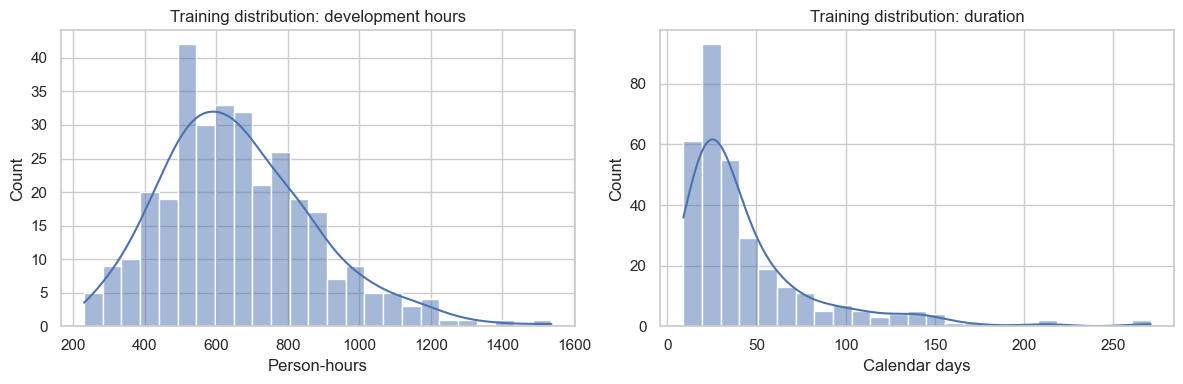

In [310]:
fig_dist, ax_dist = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    y_train["development_hours"],
    bins=25,
    kde=True,
    ax=ax_dist[0],
)
ax_dist[0].set_title("Training distribution: development hours")
ax_dist[0].set_xlabel("Person-hours")

sns.histplot(
    y_train["duration_days"],
    bins=25,
    kde=True,
    ax=ax_dist[1],
)
ax_dist[1].set_title("Training distribution: duration")
ax_dist[1].set_xlabel("Calendar days")

fig_dist.tight_layout()
plt.show()

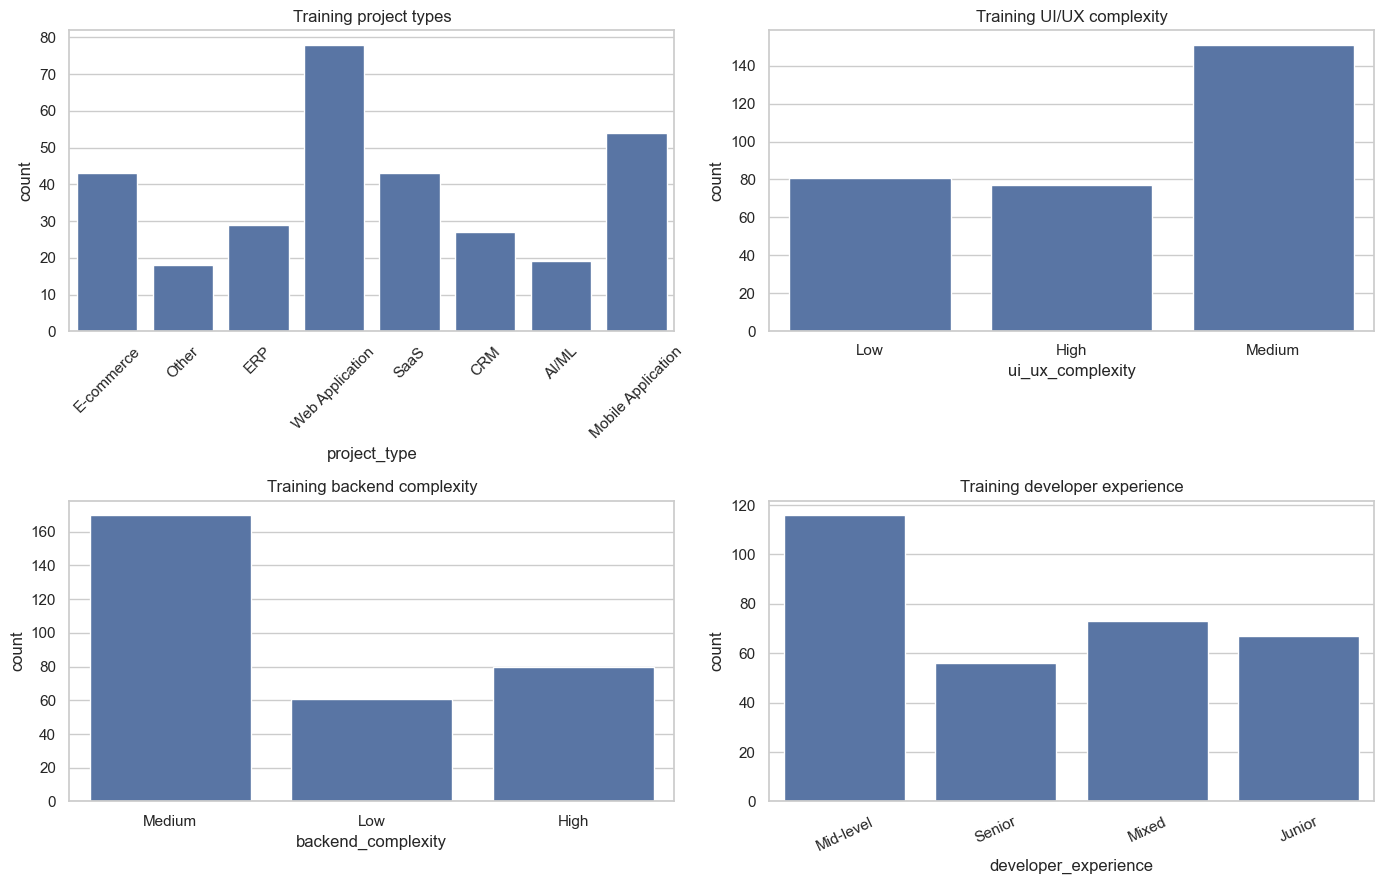

In [311]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.countplot(data=X_train, x="project_type", ax=axes[0, 0])
axes[0, 0].set_title("Training project types")
axes[0, 0].tick_params(axis="x", rotation=45)

sns.countplot(data=X_train, x="ui_ux_complexity", ax=axes[0, 1])
axes[0, 1].set_title("Training UI/UX complexity")

sns.countplot(data=X_train, x="backend_complexity", ax=axes[1, 0])
axes[1, 0].set_title("Training backend complexity")

sns.countplot(data=X_train, x="developer_experience", ax=axes[1, 1])
axes[1, 1].set_title("Training developer experience")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

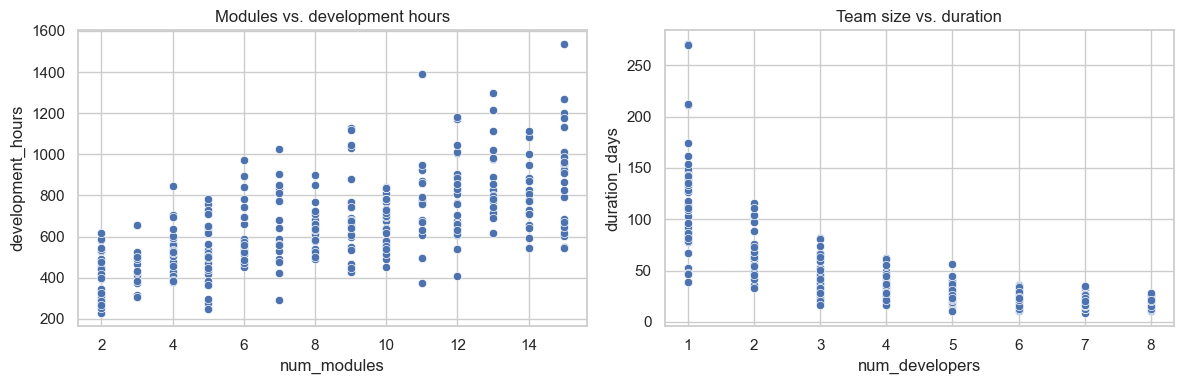

In [312]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(
    x=X_train["num_modules"],
    y=y_train["development_hours"],
    ax=axes[0],
)
axes[0].set_title("Modules vs. development hours")

sns.scatterplot(
    x=X_train["num_developers"],
    y=y_train["duration_days"],
    ax=axes[1],
)
axes[1].set_title("Team size vs. duration")

plt.tight_layout()
plt.show()

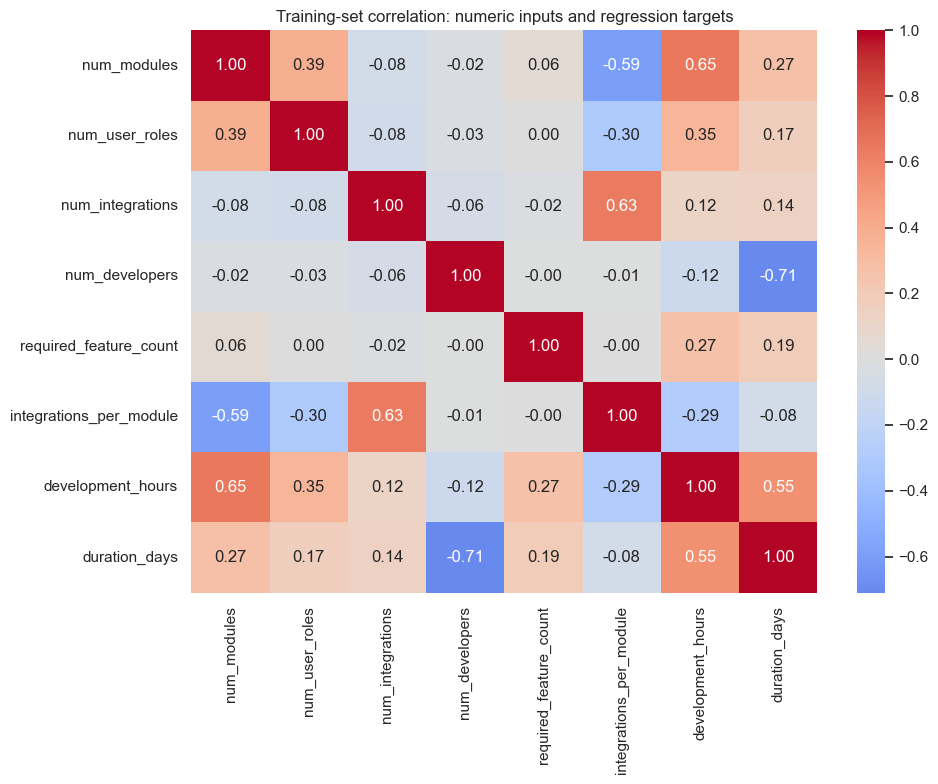

In [313]:
heatmap_data = X_train[NUMERIC_FEATURES].copy()
heatmap_data["development_hours"] = y_train["development_hours"]
heatmap_data["duration_days"] = y_train["duration_days"]

plt.figure(figsize=(10, 8))
sns.heatmap(
    heatmap_data.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
)
plt.title("Training-set correlation: numeric inputs and regression targets")
plt.tight_layout()
plt.show()

# building preprocessing

In [314]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ])

%pip install xgboost
from xgboost import XGBRegressor
candidate_models = {
    "Dummy Median Baseline": DummyRegressor(strategy="median"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        eval_metric="mae",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
}

from sklearn.model_selection import RepeatedKFold
cv = RepeatedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=RANDOM_STATE,
)


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [315]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

cv_rows = []

for target in MODEL_TARGETS:
    for model_name, estimator in candidate_models.items():
        pipeline = Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", clone(estimator)),
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train[target],
            cv=cv,
            scoring=scoring,
            return_train_score=False,
            n_jobs=-1,
            error_score="raise",
        )

        cv_rows.append({
            "target": target,
            "model": model_name,
            "CV_MAE_mean": -scores["test_MAE"].mean(),
            "CV_MAE_std": scores["test_MAE"].std(),
            "CV_RMSE_mean": -scores["test_RMSE"].mean(),
            "CV_RMSE_std": scores["test_RMSE"].std(),
            "CV_R2_mean": scores["test_R2"].mean(),
            "CV_R2_std": scores["test_R2"].std(),
        })

cv_results = pd.DataFrame(cv_rows).sort_values(
    ["target", "CV_MAE_mean"]
)

display(cv_results)

,target,model,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_R2_std
1,development_hours,Linear Regression,97.091005,11.014498,127.298661,14.119640,0.643410,0.063963
3,development_hours,XGBoost,105.775925,10.758495,140.255475,16.622533,0.570214,0.063673
2,development_hours,Random Forest,113.608523,13.540661,149.027665,19.213622,0.515662,0.071592
0,development_hours,Dummy Median Baseline,168.436875,14.579379,217.357139,19.894700,-0.027966,0.036721
7,duration_days,XGBoost,10.103378,1.783559,18.007028,5.191993,0.778797,0.063459
6,duration_days,Random Forest,10.401484,1.591139,17.604826,4.437484,0.784404,0.063888
5,duration_days,Linear Regression,17.493027,2.108162,25.294080,5.374886,0.561677,0.059568
4,duration_days,Dummy Median Baseline,23.979375,3.727843,40.779481,8.462425,-0.129370,0.053077


In [316]:
selected_models = {}

for target in MODEL_TARGETS:
    target_results = cv_results[cv_results["target"] == target]
    winner = target_results.sort_values("CV_MAE_mean").iloc[0]["model"]
    selected_models[target] = winner

print("Selected using training-only CV MAE:")
print(selected_models)

Selected using training-only CV MAE:
{'development_hours': 'Linear Regression', 'duration_days': 'XGBoost'}


In [317]:
fitted_candidates = {}
holdout_rows = []

for target in MODEL_TARGETS:
    for model_name, estimator in candidate_models.items():
        pipeline = Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", clone(estimator)),
        ])

        pipeline.fit(X_train, y_train[target])
        predictions = pipeline.predict(X_test)

        fitted_candidates[(target, model_name)] = pipeline

        holdout_rows.append({
            "target": target,
            "model": model_name,
            "selected_by_training_CV": model_name == selected_models[target],
            "test_MAE": mean_absolute_error(y_test[target], predictions),
            "test_RMSE": np.sqrt(
                mean_squared_error(y_test[target], predictions)
            ),
            "test_R2": r2_score(y_test[target], predictions),
        })

holdout_results = pd.DataFrame(holdout_rows).sort_values(
    ["target", "test_MAE"]
)

display(holdout_results)

,target,model,selected_by_training_CV,test_MAE,test_RMSE,test_R2
3,development_hours,XGBoost,False,96.344172,157.774293,0.578740
1,development_hours,Linear Regression,True,97.264667,144.072148,0.648733
2,development_hours,Random Forest,False,102.647423,167.319126,0.526229
0,development_hours,Dummy Median Baseline,False,177.287500,244.074604,-0.008144
7,duration_days,XGBoost,True,8.575567,14.342023,0.889208
6,duration_days,Random Forest,False,9.228127,14.836733,0.881433
5,duration_days,Linear Regression,False,18.821043,26.591382,0.619136
4,duration_days,Dummy Median Baseline,False,26.012500,45.769941,-0.128364


In [318]:
final_models = {
    target: fitted_candidates[(target, selected_models[target])]
    for target in MODEL_TARGETS
}

print("Final model for hours:", selected_models["development_hours"])
print("Final model for duration:", selected_models["duration_days"])

Final model for hours: Linear Regression
Final model for duration: XGBoost


In [319]:
hours_test_mask = y_test["development_hours"].notna()

predicted_hours_test = final_models["development_hours"].predict(
    X_test.loc[hours_test_mask]
)
predicted_cost_test = predicted_hours_test * RATE_INR_PER_HOUR

actual_cost_test = model_df.loc[
    y_test.index[hours_test_mask],
    "development_cost_inr",
]

cost_metrics = pd.DataFrame([{
    "assumed_rate_INR_per_hour": RATE_INR_PER_HOUR,
    "cost_MAE_INR": mean_absolute_error(
        actual_cost_test,
        predicted_cost_test,
    ),
    "cost_RMSE_INR": np.sqrt(
        mean_squared_error(actual_cost_test, predicted_cost_test)
    ),
}])

display(cost_metrics)

,assumed_rate_INR_per_hour,cost_MAE_INR,cost_RMSE_INR
0,1200,116717.600285,172886.577025


Permutation importance for development_hours:


,feature,importance_mean,importance_std
1,num_modules,87.011154,8.189433
11,developer_experience,22.174315,4.505283
9,backend_complexity,16.985877,3.700062
3,num_integrations,14.809701,2.001758
8,ui_ux_complexity,10.216657,2.062620
12,required_feature_count,9.877983,2.794273
7,ai_ml_required,7.465115,3.201910
2,num_user_roles,6.495460,2.480552
6,mobile_app_required,1.860795,1.687893
10,num_developers,0.620813,1.163789


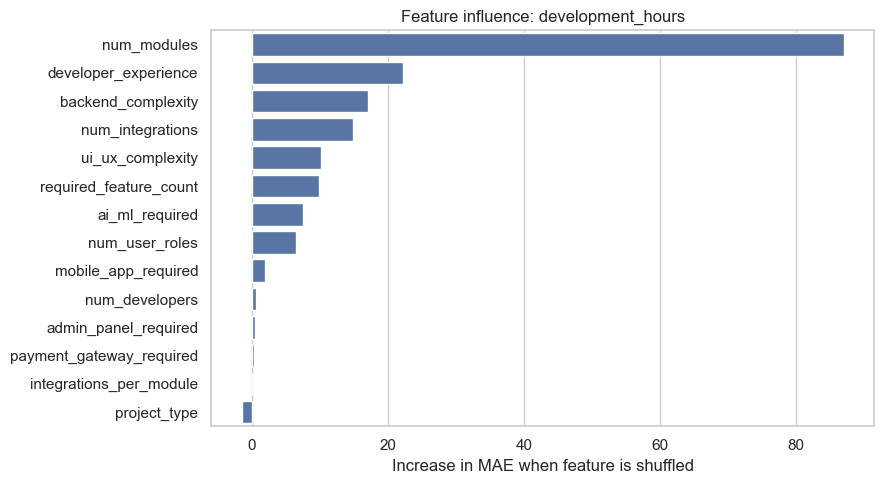

Permutation importance for duration_days:


,feature,importance_mean,importance_std
10,num_developers,25.266377,2.635593
1,num_modules,7.243538,1.090444
3,num_integrations,1.212697,0.272554
11,developer_experience,0.988324,0.184603
9,backend_complexity,0.719217,0.173039
13,integrations_per_module,0.320543,0.232750
8,ui_ux_complexity,0.259522,0.265939
6,mobile_app_required,0.176479,0.190209
7,ai_ml_required,0.171448,0.183309
12,required_feature_count,0.125332,0.193016


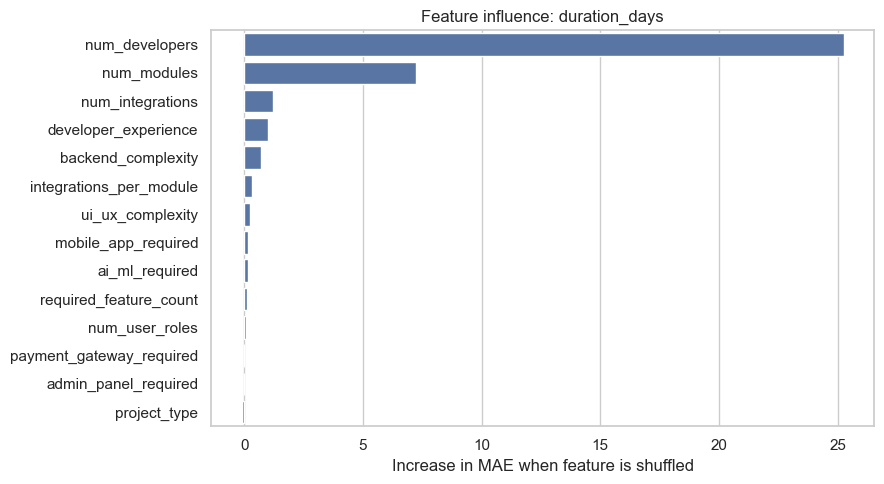

In [320]:
importance_tables = {}

for target in MODEL_TARGETS:
    model = final_models[target]

    y_for_target = y_test[target]

    result = permutation_importance(
        model,
        X_test,
        y_for_target,
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    importance_df = pd.DataFrame({
        "feature": FEATURES,
        "importance_mean": result.importances_mean,
        "importance_std": result.importances_std,
    }).sort_values("importance_mean", ascending=False)

    importance_tables[target] = importance_df

    print(f"Permutation importance for {target}:")
    display(importance_df)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=importance_df,
        x="importance_mean",
        y="feature",
    )
    plt.title(f"Feature influence: {target}")
    plt.xlabel("Increase in MAE when feature is shuffled")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

In [321]:
COMPLEXITY_POINTS = {
    "Low": 0,
    "Medium": 1,
    "High": 2,
}

COMPLEXITY_INPUTS = [
    "num_modules",
    "num_user_roles",
    "num_integrations",
    "payment_gateway_required",
    "admin_panel_required",
    "mobile_app_required",
    "ai_ml_required",
    "ui_ux_complexity",
    "backend_complexity",
]


def calculate_complexity(row):
    if any(pd.isna(row[column]) for column in COMPLEXITY_INPUTS):
        return np.nan

    score = (
        row["num_modules"] / 3
        + row["num_user_roles"] / 2
        + row["num_integrations"] * 0.8
        + (row["payment_gateway_required"] == "Yes") * 1.0
        + (row["admin_panel_required"] == "Yes") * 0.5
        + (row["mobile_app_required"] == "Yes") * 1.5
        + (row["ai_ml_required"] == "Yes") * 2.0
        + COMPLEXITY_POINTS[row["ui_ux_complexity"]] * 1.0
        + COMPLEXITY_POINTS[row["backend_complexity"]] * 1.2
    )

    if score <= 7:
        return "Low"
    elif score <= 12:
        return "Medium"
    elif score <= 14:
        return "High"
    return "Very High"


complexity_check = df[COMPLEXITY_INPUTS + ["complexity_level"]].copy()
complexity_check["calculated_complexity"] = complexity_check.apply(
    calculate_complexity,
    axis=1,
)

complete_complexity_rows = complexity_check.dropna(
    subset=COMPLEXITY_INPUTS + ["complexity_level"]
)

agreement = (
    complete_complexity_rows["calculated_complexity"]
    == complete_complexity_rows["complexity_level"]
).mean()

print("Complete rows checked:", len(complete_complexity_rows))
print("Agreement with synthetic rule:", round(agreement, 4))
print("\nGenerated complexity distribution:")
display(df["complexity_level"].value_counts().to_frame("projects"))

Complete rows checked: 344
Agreement with synthetic rule: 1.0

Generated complexity distribution:


,projects
complexity_level,
Medium,221
High,86
Very High,59
Low,34


In [322]:
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

joblib.dump(
    final_models["development_hours"],
    model_dir / "development_hours_model.joblib",
)

joblib.dump(
    final_models["duration_days"],
    model_dir / "duration_days_model.joblib",
)

cv_results.to_csv("data/cross_validation_results.csv", index=False)
holdout_results.to_csv("data/holdout_test_results.csv", index=False)
cost_metrics.to_csv("data/derived_cost_metrics.csv", index=False)

for target, table in importance_tables.items():
    safe_name = target.replace("/", "_")
    table.to_csv(
        f"data/feature_importance_{safe_name}.csv",
        index=False,
    )

print("Saved fitted models to:", model_dir)

Saved fitted models to: models
